---
title: "CNN Implementation"
---

### Training CNN Model using MNIST Dataset

For this demonstration we will be using MNIST dataset which is a popular dataset in training deep learning models.


> **Changes needed to run the provided cells** (each marked `# fixed:` in the code):
> `EdgeDetection` referenced `T`, which is never imported; `torch.save` wrote into a `model/` folder
> that did not exist; and the loss plot assumed 5,000 / 1,000 batches per epoch, although the
> 80/20 split gives 4,800 / 1,200. Everything else runs as provided.

#### Import Standard Libraries


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms

import random
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
%matplotlib inline
from PIL import Image

torch.backends.cudnn.deterministic=True
torch.set_printoptions(sci_mode=False)

import time
from tqdm.notebook import tqdm

`torchvision.datasets` module provides a variety of datasets that are commonly used for training machine learning and deep learning models. These datasets are preprocessed and can be easily integrated into PyTorch workflows for tasks such as image classification, object detection, and more. Dataset includes:

- MNIST
- CIFAR10
- CIFAR100
- ImageNet


In [2]:
class EdgeDetection:
    """Custom transform to perform edge detection on grayscale images."""
    def __init__(self):
        # Sobel kernels for x and y directions
        self.sobel_x = torch.tensor([[1, 0, -1],
                                     [2, 0, -2],
                                     [1, 0, -1]], dtype=torch.float32).unsqueeze(0).unsqueeze(0)  # shape (1,1,3,3)
        self.sobel_y = torch.tensor([[1, 2, 1],
                                     [0, 0, 0],
                                     [-1, -2, -1]], dtype=torch.float32).unsqueeze(0).unsqueeze(0)

    def __call__(self, img):
        """
        Args:
            img (PIL.Image or torch.Tensor): Input grayscale image.
        Returns:
            torch.Tensor: Edge-detected image.
        """
        if isinstance(img, Image.Image):
            img = transforms.ToTensor()(img)  # fixed: `T` was never imported  # convert PIL to tensor, shape (C,H,W)
        if img.ndim == 3 and img.shape[0] != 1:
            # MNIST is grayscale; ensure single channel
            img = img.mean(dim=0, keepdim=True)

        img = img.unsqueeze(0)  # add batch dim: (1,1,H,W)
        
        # Convolve with Sobel filters
        grad_x = F.conv2d(img, self.sobel_x, padding=1)
        grad_y = F.conv2d(img, self.sobel_y, padding=1)
        
        # Compute gradient magnitude
        edges = torch.sqrt(grad_x**2 + grad_y**2)
        edges = edges.squeeze(0)  # remove batch dim

        # Normalize to 0-1
        edges = (edges - edges.min()) / (edges.max() - edges.min() + 1e-6)
        return edges

In [3]:
# `transforms` is used to apply augmentation techniques and modification to the image data (e.g, rotate, resize, normalization, etc.).
# for this one, let's just convert the image arrays to tensor.
transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.Resize((64, 64)),
    # EdgeDetection()
])

train_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data  = datasets.MNIST(root='data', train=False, download=True, transform=transform)

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<01:09, 143kB/s]

  1%|          | 98.3k/9.91M [00:00<00:43, 225kB/s]

  2%|▏         | 197k/9.91M [00:00<00:31, 313kB/s] 

  4%|▍         | 393k/9.91M [00:00<00:18, 526kB/s]

  8%|▊         | 819k/9.91M [00:01<00:09, 996kB/s]

... (16 outputs left out)

 66%|██████▌   | 1.08M/1.65M [00:01<00:00, 1.16MB/s]

100%|██████████| 1.65M/1.65M [00:01<00:00, 1.14MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 4.55MB/s]

In [4]:
# the training data have 60,000 images, let's take a small portion from it for the validation.
# what's the importance of validation data?
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [5]:
# unseen images
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [6]:
# function to set the seed
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    random.seed(seed)

In [7]:
# 80/20 split of the 60,000 training images: 48,000 for training and 12,000 for validation

set_seed(42)
train_set, val_set = torch.utils.data.random_split(train_data, [0.8, 0.2])

PyTorch provides two data primitives: `torch.utils.data.DataLoader` and `torch.utils.data.Dataset` that allow you to use pre-loaded datasets as well as your own data. Dataset stores the samples and their corresponding labels, and DataLoader wraps an iterable around the Dataset to enable easy access to the samples.


In [8]:
set_seed(143)

batch_size = 10

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

In [9]:
for batch in train_loader:
    print(len(batch[0]))
    print(len(batch[1]))
    break

10
10


In [10]:
batch[0].shape # b, c, h, w

torch.Size([10, 1, 28, 28])

In [11]:
set_seed(143)
images, labels = iter(train_loader).__next__()

def display_image(batch):
    batch = batch.detach().numpy()
    fig, axs = plt.subplots(1, len(batch), figsize=(12, 2))
    for i in range(len(batch)):
        axs[i].imshow(batch[i, 0, :, :], vmin=0, vmax=1)
        axs[i].axis('off')
        axs[i].set_title(labels[i].numpy())
    plt.show()

For this demonstration, we will use the following architecture: it consists of two convolutional layers, each followed by its own max-pooling layer and activation function. Additionally, there are two fully connected layers, with the second layer using the softmax activation function.

*[Figure `figures/lecture_model.png` belongs to the course handout and was not distributed with this notebook.]*


#### Input Images


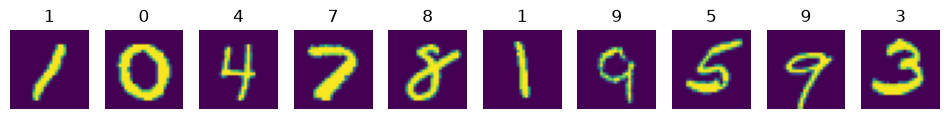

torch.Size([10, 1, 28, 28])


In [12]:
display_image(images)
print(images.shape)

# (b, c, h, w)

$$\text{Output Shape} = \frac{\text{input width} - \text{filter} + 2 \cdot \text{padding}}{\text{stride} + 1}$$

In [13]:
def calc_out(w, f, s, p):
    """
    Calculate output shape of a matrix after a convolution.
    The results are only applicable for square matrix kernels and images only.
    """
    print(f'Output Shape: {(w - f + 2 * p) // s + 1}')

#### First Convolution Layer + Activation Function


In [14]:
# The first convolution must output a 28 by 28 image size
calc_out(28, 3, 1, 1)

Output Shape: 28


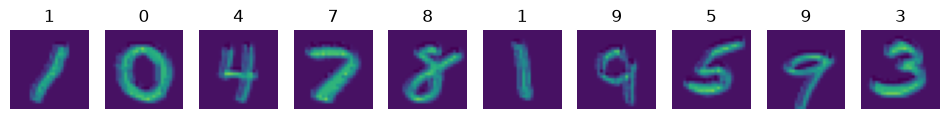

torch.Size([10, 32, 28, 28])


In [15]:
conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=(3,3), stride=1, padding=1)

x = F.relu(conv1(images))
display_image(x)
print(x.shape)

#### First Pooling (MaxPooling)


In [16]:
# first maxpooling must output a 14 by 14 size
calc_out(28, 2, 2, 0)

Output Shape: 14


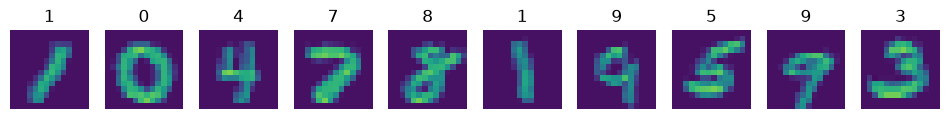

torch.Size([10, 32, 14, 14])


In [17]:
pool1 = nn.MaxPool2d(kernel_size=(2,2), stride=2)

x = pool1(x)
display_image(x)
print(x.shape)

#### Let's examine the feature map.


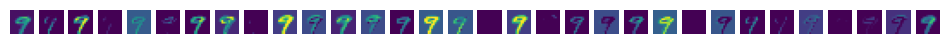

In [18]:
idx = -2
feature_maps =  x[idx].view((1, 32, 14, 14)).detach().numpy()
fig, axs = plt.subplots(1, 32, figsize=(12, 2))
for i in range(32):
    axs[i].imshow(feature_maps[0, i, :, :], vmin=0, vmax=1)
    axs[i].axis('off')

#### Second Convolution


In [19]:
calc_out(14, 3, 1, 1)

Output Shape: 14


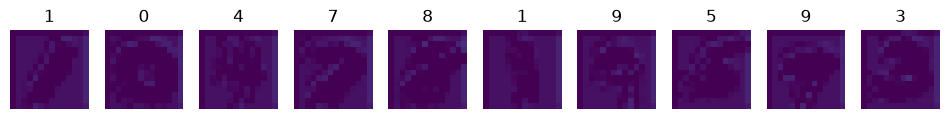

torch.Size([10, 64, 14, 14])


In [20]:
conv2 = nn.Conv2d(32, 64, (3,3), 1, 1)

x = F.relu(conv2(x))
display_image(x)
print(x.shape)

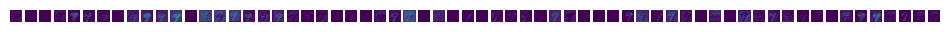

In [21]:
idx = -2
feature_maps =  x[idx].view((1, 64, 14, 14)).detach().numpy()
fig, axs = plt.subplots(1, 64, figsize=(12, 2))
for i in range(64):
    axs[i].imshow(feature_maps[0, i, :, :], vmin=0, vmax=1)
    axs[i].axis('off')

#### Second Pooling (MaxPooling)


In [22]:
calc_out(14, 2, 2, 0)

Output Shape: 7


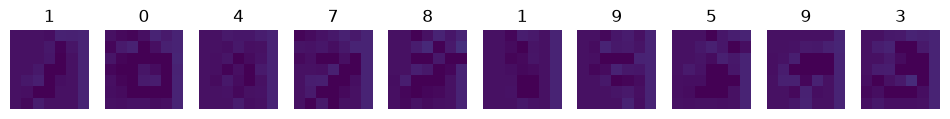

torch.Size([10, 64, 7, 7])


In [23]:
pool2 = nn.MaxPool2d((2,2), 2)

x = pool2(x)
display_image(x)
print(x.shape)

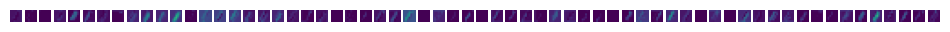

In [24]:
idx = 0
feature_maps =  x[idx].view((1, 64, 7, 7)).detach().numpy()
fig, axs = plt.subplots(1, 64, figsize=(12, 2))
for i in range(64):
    axs[i].imshow(feature_maps[0, i, :, :], vmin=0, vmax=1)
    axs[i].axis('off')

#### Flatten


In [25]:
64 * 7 * 7

3136

In [26]:
flat = x.view((-1, 64*7*7)) # each instance contains 3136 data

fcn1 = nn.Linear(64*7*7, 128)
fcn2 = nn.Linear(128, 10)

out = fcn1(flat)
out = F.softmax(fcn2(out), dim=1)

In [27]:
# prediction
# assess the prediction
[i.argmax().item() for i in out]

[4, 4, 8, 4, 4, 8, 8, 4, 4, 4]

In [28]:
# true label
[i.item() for i in labels]

[1, 0, 4, 7, 8, 1, 9, 5, 9, 3]

**QUESTION:**

Why is it that the true and the predicted value is very distant from each other?


**Answer.** Nothing has been learned yet. `conv1`, `conv2`, `fcn1` and `fcn2` were created a few
cells earlier, so their weights are random numbers from PyTorch's default initialisation, and no
training step (forward → loss → `backward()` → optimizer update) has happened. The forward pass
is therefore an arbitrary function of the pixels. The softmax outputs sit close to $1/10$ for
every class, so the `argmax` is effectively a coin flip among ten options, and any match with the
true label is luck. The predictions also repeat the same few classes: an untrained network maps
similar-looking inputs to similar outputs, and all digits share a dark background. Only training
shapes the weights so that the outputs line up with the labels, as the training loop below shows.

In [29]:
probs = out.detach()
print("largest softmax probability per image:", probs.max(dim=1).values.numpy().round(3))
print("smallest                             :", probs.min(dim=1).values.numpy().round(3))
print("a uniform guess would give 0.1 for every class")

largest softmax probability per image: [0.11  0.109 0.113 0.111 0.112 0.11  0.113 0.112 0.112 0.112]
smallest                             : [0.093 0.091 0.092 0.093 0.091 0.091 0.092 0.091 0.092 0.091]
a uniform guess would give 0.1 for every class


#### Now let's put them all together


In [30]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        # just the initialization
        self.conv1 = nn.Conv2d(1, 32, (3,3), 1, 1)
        self.pool1 = nn.MaxPool2d((2,2), 2)
        self.conv2 = nn.Conv2d(32, 64, (3,3), 1, 1)
        self.pool2 = nn.MaxPool2d((2,2), 2)
        self.fcn1 = nn.Linear(64*7*7, 128)
        self.fcn2 = nn.Linear(128, 10)

    def forward(self, x):
        # seuential
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        x = x.view(-1, 64*7*7)
        x = self.fcn1(x)
        x = F.softmax(self.fcn2(x), dim=1)
        
        return x

#### Instantiate the Class


In [31]:
model = CNN()
model

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dilation=1, ceil_mode=False)
  (fcn1): Linear(in_features=3136, out_features=128, bias=True)
  (fcn2): Linear(in_features=128, out_features=10, bias=True)
)

Model Parameters:

$$\begin{aligned}(1\times32\times3\times3)+32+(32\times64\times3\times3)+64+(3136\times128)+128+(128\times10)+10 &=\\
288+32+18432+64+401408+128+1280+10 &= 421,642\end{aligned}$$


In [32]:
def count_parameters(model):
    params = [p.numel() for p in model.parameters() if p.requires_grad]
    for item in params:
        print(f'{item:>6}')
    print(f'______\n{sum(params):>6}')

count_parameters(model)

   288
    32
 18432
    64
401408
   128
  1280
    10
______
421642


#### Define Criterion and Optimizer


In [33]:
criterion = nn.CrossEntropyLoss() # loss functions
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [34]:
# if your device has cuda enabled gpu, you can use it to accelerate the training process.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(device)

model = model.to(device)

cuda


In [35]:
next(model.parameters()).device

device(type='cuda', index=0)

#### Let's walk through the training loop

```python
for e in range(epochs):
train_corr = 0
val_corr = 0
```

This will iterate `5` times as what is defined below. `train_corr` and `val_corr` serves as temporary place holders for correctly predicted train data and correctly predicted validation data. Hence, `train_corr` and `val_corr` will be re-initialized to `0` again if an entire epoch is done.

```python
for train_b, (x_train, y_train) in tqdm(enumerate(train_loader)):
train_b += 1
x_train = x_train.to(device)
y_train = y_train.to(device)
```

The second loop (nested loop) iterates over the `train_loader`. A single iteration of the `train_loader` is equal to `1` batch of features and targets, our batch size is 10, therefore in every iteration of the `train_loader` we are processing `10` instances. The entire training set or the `len(train_loader.dataset)` is `50,000`. Therefore, to finish an entire epoch, we need to process `5000` batches with a batch size of `10` (5000 x 10 = 50,000).

**NOTE:**
When an iterable object is wrapped around an `enumerate` function, the output will return an index for each iterated values. `train_b` is the number of batches that has been processed.

The `to()` functions next to the `x_train` and `y_train` are simply there to move the data into the available computing device. Remember that you need to move the `model` as well to the available device.

**OUTPUT:**

`x_train.shape` = `torch.Size([10, 1, 28, 28])`

`y_train.shape` = `torch.Size([10])`

```python
train_pred = model(x_train)
train_loss = criterion(train_pred, y_train)

train_pred_vec = torch.max(train_pred.data, 1)[1]
train_corr += (train_pred_vec == y_train).sum()
```
`train_pred` represents the model's predictions for the current batch. The shape of train_pred is `torch.Size([10, 10])`. Each row in `train_pred` corresponds to an instance in the batch, and each column represents a class. The values in each row indicate the model's estimated probabilities or scores for each class for that instance.

`train_loss` is a scalar value of the error that was calculated from that particular batch.

`train_pred_vec` is a vector that contained the predicted labels of the current batch. The values are integer that ranges from 0 to 9. `train_pred_vec.shape` is `torch.Size([10])`, the values represents each predicted label of each instance.

`train_corr` performs comparison operation to check how many samples in the batch was correctly predicted, the value of the `train_corr` will be inceremented, but will be re-initialized back to 0 when an entire epoch is done.

```python
# Update parameters
optimizer.zero_grad()
train_loss.backward()
optimizer.step()
```
We need to update the parameters for every batch that passes in every epoch, we can do this by applying `zero_grad()` to the optimizer, this will clear the gradients for the next batch, if we don't do that, the gradients will accumulate for every batch for the entire epoch.

`train_loss.backward()` is used to compute the gradients of the loss with respect to the model's parameters during the backward pass of the training process. It's a fundamental step in the training loop of a neural network.

`optimizer.step()` is a method used to update the parameters (weights and biases) of a neural network model during the training process. It is called after the gradients of the model's parameters have been computed during the backward pass.

```python
if train_b % 1250 == 0:
print(f"epoch: {e+1:2} | batch: {train_b:4} | instances: [{train_b*batch_size:6} / {len(train_loader)  * batch_size}] | loss: {train_loss.item()}")
print(f"✅{train_corr.item()} of {train_b*batch_size:2} | accuracy: {round(((train_corr.item() / (train_b*batch_size))) * 100 , 3)}%")
```
This prints training progress information during each batch iteration in a concise format. It displays the current epoch, batch number, the number of processed instances, the loss, and the accuracy achieved up to that point in training.

```python
train_correct.append(train_corr.item())
train_losses.append(train_loss.item())
```
Appends current the batch's `train_corr` and `train_loss` on the empty lists outside the epoch.

```python
with torch.no_grad():
for val_b, (x_val, y_val) in enumerate(val_loader):
val_b += 1

x_val = x_val.to(device)
y_val = y_val.to(device)

val_pred = model(x_val)
val_pred_vec = torch.max(val_pred.data, 1)[1]
val_corr += (val_pred_vec == y_val).sum()

val_loss = criterion(val_pred, y_val)
val_correct.append(val_corr.item())
val_losses.append(val_loss.item())

val_acc = val_corr.item() / (len(val_loader) * batch_size)

if val_acc > best_acc:
best_acc = val_acc
torch.save(model.state_dict(), f"model/best_{model._get_name()}.pth")
print(f"\t📁New best model saved! | accuracy: {best_acc*100}%")

train_epoch_acc = train_corr.item() / (batch_size * len(train_loader))
val_epoch_acc = val_corr.item() / (batch_size * len(val_loader))

train_accs.append(train_epoch_acc)
val_accs.append(val_epoch_acc)

print(f'\nDuration: {time.time() - start_time:.0f} seconds')
```
This part of the code performs the evaluation of the trained model for every epoch, the code is quite similar to the training process but without the updating of parameters. The code also have features of saving the `state_dict` (trained parameters) of the model with best accuracy.


In [36]:
import os
os.makedirs("model", exist_ok=True)  # fixed: torch.save below needs the folder

set_seed(42)
epochs = 5
start_time = time.time()
best_acc = 0.0

train_correct = []
train_losses = []
train_accs = []

val_correct = []
val_losses = []
val_accs = []

for e in range(epochs):
    train_corr = 0
    val_corr = 0
    
    for train_b, (x_train, y_train) in tqdm(enumerate(train_loader)):
        train_b += 1
        x_train = x_train.to(device)
        y_train = y_train.to(device)

        train_pred = model(x_train) # model.fit(X_train, y_train) --> model.score(X_test)
        train_loss = criterion(train_pred, y_train)

        train_pred_vec = torch.max(train_pred.data, 1)[1] # prediction vector
        train_corr += (train_pred_vec == y_train).sum()

        # Update parameters
        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if train_b % 1250 == 0:
            print(f"epoch: {e+1:2} | batch: {train_b:4} | instances: [{train_b*batch_size:6} / {len(train_loader)  * batch_size}] | loss: {train_loss.item()}")
            print(f"✅{train_corr.item()} of {train_b*batch_size:2} | accuracy: {round(((train_corr.item() / (train_b*batch_size))) * 100 , 3)}%")

        train_correct.append(train_corr.item())
        train_losses.append(train_loss.item())

    with torch.no_grad():
        for val_b, (x_val, y_val) in enumerate(val_loader):
            val_b += 1
            
            x_val = x_val.to(device)
            y_val = y_val.to(device)

            val_pred = model(x_val)
            val_pred_vec = torch.max(val_pred.data, 1)[1]
            val_corr += (val_pred_vec == y_val).sum()

            val_loss = criterion(val_pred, y_val)
            val_correct.append(val_corr.item())
            val_losses.append(val_loss.item())
            
            val_acc = val_corr.item() / (len(val_loader) * batch_size)
            
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), f"model/best_{model._get_name()}.pth")
            print(f"\t📁New best model saved! | accuracy: {best_acc*100}%")
    
    train_epoch_acc = train_corr.item() / (batch_size * len(train_loader))
    val_epoch_acc = val_corr.item() / (batch_size * len(val_loader))
    
    train_accs.append(train_epoch_acc)
    val_accs.append(val_epoch_acc)

print(f'\nDuration: {time.time() - start_time:.0f} seconds')

0it [00:00, ?it/s]

epoch:  1 | batch: 1250 | instances: [ 12500 / 48000] | loss: 1.4614139795303345
✅11023 of 12500 | accuracy: 88.184%


epoch:  1 | batch: 2500 | instances: [ 25000 / 48000] | loss: 1.5453559160232544
✅22951 of 25000 | accuracy: 91.804%


epoch:  1 | batch: 3750 | instances: [ 37500 / 48000] | loss: 1.563601016998291
✅34971 of 37500 | accuracy: 93.256%


	📁New best model saved! | accuracy: 96.85833333333333%


0it [00:00, ?it/s]

... (14 outputs left out)

epoch:  5 | batch: 1250 | instances: [ 12500 / 48000] | loss: 1.4611502885818481
✅12087 of 12500 | accuracy: 96.696%


epoch:  5 | batch: 2500 | instances: [ 25000 / 48000] | loss: 1.5611501932144165
✅24196 of 25000 | accuracy: 96.784%


epoch:  5 | batch: 3750 | instances: [ 37500 / 48000] | loss: 1.561150312423706
✅36364 of 37500 | accuracy: 96.971%


	📁New best model saved! | accuracy: 97.21666666666667%

Duration: 398 seconds


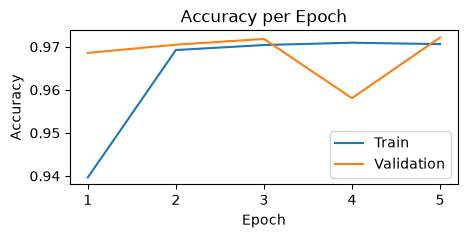

In [37]:
plt.figure(figsize=(5,2))
plt.plot(train_accs, label="Train")
plt.plot(val_accs, label="Validation")
plt.xticks(ticks=range(0,5), labels=list(range(1,6)))
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy per Epoch")
plt.legend()
plt.show()

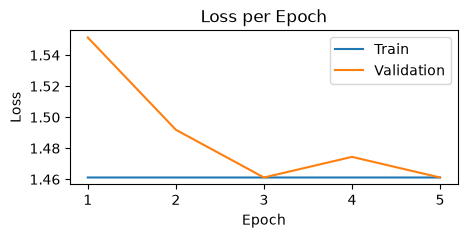

In [38]:
plt.figure(figsize=(5,2))
plt.plot([train_losses[i-1] for i in range(len(train_loader), len(train_losses)+1, len(train_loader))], label="Train")
plt.plot([val_losses[i-1] for i in range(len(val_loader), len(val_losses)+1, len(val_loader))], label="Validation")
plt.xticks(ticks=range(0,5), labels=list(range(1,6)))
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss per Epoch")
plt.legend()
plt.show()

#### Testing


In [39]:
true_labels = []
pred_labels = []

with torch.no_grad():
    for b, (x_test, y_test) in enumerate(test_loader):
        
        x_test = x_test.to(device)
        y_test = y_test.to(device)
        
        test_pred = model(x_test)
        test_pred_vec = torch.max(test_pred.data, 1)[1]

        true_labels.append(y_test)
        pred_labels.append(test_pred_vec)

In [40]:
true_labels = torch.cat(true_labels, dim=0)
pred_labels = torch.cat(pred_labels, dim=0)

#### Classification Matrix


In [41]:
[v for k,v in train_data.class_to_idx.items()]

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [42]:
true_labels

tensor([7, 2, 1,  ..., 4, 5, 6], device='cuda:0')

In [43]:
pred_labels

tensor([7, 2, 1,  ..., 4, 5, 6], device='cuda:0')

In [44]:
np.set_printoptions(formatter=dict(int=lambda x: f'{x:3}'))
print(np.array([v for k,v in train_data.class_to_idx.items()]), '\n')
print(confusion_matrix(true_labels.to('cpu'), pred_labels.to('cpu')))

[  0   1   2   3   4   5   6   7   8   9] 

[[965   0   2   0   0   0   1   2   1   9]
 [  0 1102   2   2   2   0   8   4  15   0]
 [  1   0 1007   5   4   0   1  11   2   1]
 [  0   0   2 994   0   5   0   4   3   2]
 [  0   0   0   1 958   0   4   0   1  18]
 [  2   0   0   6   0 872   2   3   1   6]
 [  8   2   0   0   1   2 928   0  16   1]
 [  0   0   7   3   0   1   0 1010   1   6]
 [  4   0   1   0   1   1   0   3 958   6]
 [  0   0   0   0   5   2   0   2   6 994]]


#### Let's assess the misses


In [45]:
true_labels

tensor([7, 2, 1,  ..., 4, 5, 6], device='cuda:0')

In [46]:
misses = np.array([])
missed_label = np.array([])

for i in range(len(pred_labels.to('cpu'))):
    if pred_labels[i] != true_labels.to('cpu')[i]:
        misses = np.append(misses,i).astype('int64')
        missed_label = np.append(missed_label, true_labels.to('cpu')[i]).astype('int64')

len(misses)

212

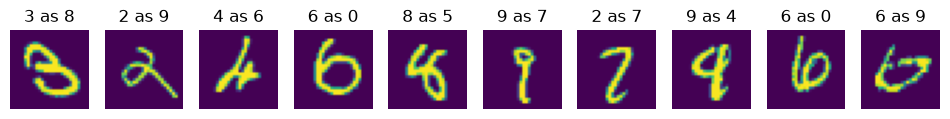

In [47]:
wrong = [pred_labels[i].item() for i in misses[:10]]
missed_images = [test_loader.dataset[j][0] for j in [i for i in misses[:10]]]
fig, axs = plt.subplots(1, len(missed_images), figsize=(12, 2))

c = 0
for i in missed_images:
    axs[c].imshow(i.view(28, 28), vmin=0, vmax=1)
    axs[c].axis('off')
    axs[c].set_title(f"{missed_label[c]} as {wrong[c]}")
    c += 1
plt.show()

#### Laboratory Activity 6

**Instruction:** Convert the following CNN architecture diagram into a PyTorch CNN architecture.

:::{image} figures/quick_draw.png
:alt: CNN architecture diagram for Laboratory Activity 6
:width: 400px
:align: center
:::

### Laboratory Activity 6 — Solution

**Reading the diagram.** Every convolution is 3×3 with stride 1 and padding 1, so it keeps the
spatial size. Only the two pooling layers shrink it. The diagram's shapes are written for a
batch of 32 images. The cell below fills in its `?` marks with the lesson's `calc_out` helper.
Note that **MaxPool1 has `padding=1`**, which turns 28×28 into 15×15 rather than 14×14.

In [48]:
calc_out(28, 3, 1, 1)   # Conv1     (k=3, s=1, p=1): 28 -> 28
calc_out(28, 2, 2, 1)   # MaxPool1  (k=2, s=2, p=1): 28 -> 15
calc_out(15, 3, 1, 1)   # Conv2, Conv3, Conv4:        15 -> 15
calc_out(15, 2, 2, 0)   # MaxPool2  (k=2, s=2, p=0): 15 -> 7
print("FCN1 input = 256 channels x 7 x 7 =", 256 * 7 * 7)

Output Shape: 28
Output Shape: 15
Output Shape: 15
Output Shape: 7
FCN1 input = 256 channels x 7 x 7 = 12544


| Block | Layer | Output shape (batch of 32) |
|---|---|---|
| Input | — | (32, 1, 28, 28) |
| ReLU(Conv1) | `Conv2d(1, 32, 3, 1, 1)` | (32, 32, 28, 28) |
| MaxPool1 | `MaxPool2d(2, 2, padding=1)` | (32, 32, 15, 15) |
| ReLU(Conv2) | `Conv2d(32, 64, 3, 1, 1)` | (32, 64, 15, 15) |
| ReLU(Conv3) | `Conv2d(64, 128, 3, 1, 1)` | (32, 128, 15, 15) |
| ReLU(Conv4) | `Conv2d(128, 256, 3, 1, 1)` | (32, 256, 15, 15) |
| MaxPool2 | `MaxPool2d(2, 2, padding=0)` | (32, 256, 7, 7) |
| DropOut | `Dropout(p=0.2)` | (32, 256, 7, 7) |
| Flatten | — | (32, 12544) |
| ReLU(FCN1) | `Linear(12544, 1000)` | (32, 1000) |
| ReLU(FCN2) | `Linear(1000, 500)` | (32, 500) |
| SoftMax(FCN3) | `Linear(500, num_classes)` | (32, 10) for MNIST |

The diagram leaves FCN3's output as `?`, because it is the number of classes. The diagram's file
name points to Google's *Quick, Draw!* doodles, and there it would be the number of drawing
categories you train on. This notebook works with MNIST, so `num_classes=10`.

**About the final SoftMax.** `nn.CrossEntropyLoss` already applies log-softmax to its input. So
`forward()` returns the raw FCN3 outputs (logits), and the diagram's SoftMax lives in
`predict_proba()`, which is used for inference. Putting softmax inside `forward()`, as the lesson's
`CNN` class does, applies it twice during training. This squeezes the gradients and puts a floor
under the loss of $-\ln\frac{e}{e+9} \approx 1.4612$. That is exactly the value the training log
above keeps printing (`loss: 1.4611502885818481`) on batches it gets completely right.

In [49]:
class QuickDrawCNN(nn.Module):
    # The architecture from the Laboratory Activity 6 diagram.
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=(3, 3), stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=(2, 2), stride=2, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=(3, 3), stride=1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=(3, 3), stride=1, padding=1)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=(3, 3), stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=(2, 2), stride=2, padding=0)
        self.dropout = nn.Dropout(p=0.2)
        self.fcn1 = nn.Linear(256 * 7 * 7, 1000)
        self.fcn2 = nn.Linear(1000, 500)
        self.fcn3 = nn.Linear(500, num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))     # (B, 32, 15, 15)
        x = F.relu(self.conv2(x))                  # (B, 64, 15, 15)
        x = F.relu(self.conv3(x))                  # (B, 128, 15, 15)
        x = self.pool2(F.relu(self.conv4(x)))      # (B, 256, 7, 7)
        x = self.dropout(x)
        x = torch.flatten(x, start_dim=1)          # (B, 12544)
        x = F.relu(self.fcn1(x))                   # (B, 1000)
        x = F.relu(self.fcn2(x))                   # (B, 500)
        return self.fcn3(x)                        # (B, num_classes) logits

    def predict_proba(self, x):
        return F.softmax(self(x), dim=1)           # the diagram's final SoftMax


set_seed(42)
qd_model = QuickDrawCNN(num_classes=10)
qd_model

QuickDrawCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=(2, 2), stride=2, padding=1, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.2, inplace=False)
  (fcn1): Linear(in_features=12544, out_features=1000, bias=True)
  (fcn2): Linear(in_features=1000, out_features=500, bias=True)
  (fcn3): Linear(in_features=500, out_features=10, bias=True)
)

**Shape check** with a batch of 32 random images, layer by layer, against the diagram:

In [50]:
x = torch.randn(32, 1, 28, 28)
with torch.no_grad():
    h = F.relu(qd_model.conv1(x));   print(f"{'ReLU(Conv1)':<14}", tuple(h.shape))
    h = qd_model.pool1(h);           print(f"{'MaxPool1':<14}", tuple(h.shape))
    h = F.relu(qd_model.conv2(h));   print(f"{'ReLU(Conv2)':<14}", tuple(h.shape))
    h = F.relu(qd_model.conv3(h));   print(f"{'ReLU(Conv3)':<14}", tuple(h.shape))
    h = F.relu(qd_model.conv4(h));   print(f"{'ReLU(Conv4)':<14}", tuple(h.shape))
    h = qd_model.pool2(h);           print(f"{'MaxPool2':<14}", tuple(h.shape))
    h = torch.flatten(qd_model.dropout(h), 1); print(f"{'Flatten':<14}", tuple(h.shape))
    p = qd_model.eval().predict_proba(x);      print(f"{'SoftMax(FCN3)':<14}", tuple(p.shape))

assert p.shape == (32, 10) and torch.allclose(p.sum(dim=1), torch.ones(32))
count_parameters(qd_model)

ReLU(Conv1)    (32, 32, 28, 28)
MaxPool1       (32, 32, 15, 15)
ReLU(Conv2)    (32, 64, 15, 15)
ReLU(Conv3)    (32, 128, 15, 15)
ReLU(Conv4)    (32, 256, 15, 15)
MaxPool2       (32, 256, 7, 7)
Flatten        (32, 12544)


SoftMax(FCN3)  (32, 10)
   288
    32
 18432
    64
 73728
   128
294912
   256
12544000
  1000
500000
   500
  5000
    10
______
13438350


**Does it train?** A quick check on the same MNIST split, using the diagram's batch size of 32,
Adam with lr = 0.001 (as in the lesson), cross-entropy on the logits, and 3 epochs. The best
epoch on validation is kept, then the test set is scored once.

In [51]:
set_seed(42)
qd_model = QuickDrawCNN(num_classes=10).to(device)
qd_criterion = nn.CrossEntropyLoss()
qd_optimizer = torch.optim.Adam(qd_model.parameters(), lr=0.001)
qd_train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
qd_val_loader = DataLoader(val_set, batch_size=256, shuffle=False)
qd_test_loader = DataLoader(test_data, batch_size=256, shuffle=False)


def evaluate(model, loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss_sum += qd_criterion(logits, yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return loss_sum / n, correct / n


qd_hist, best_val, start = [], 0.0, time.time()
for epoch in range(3):
    qd_model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in qd_train_loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = qd_model(xb)
        loss = qd_criterion(logits, yb)
        qd_optimizer.zero_grad()
        loss.backward()
        qd_optimizer.step()
        loss_sum += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    val_loss, val_acc = evaluate(qd_model, qd_val_loader)
    qd_hist.append((loss_sum / n, correct / n, val_loss, val_acc))
    if val_acc > best_val:
        best_val = val_acc
        torch.save(qd_model.state_dict(), "model/best_QuickDrawCNN.pth")
    print(f"epoch {epoch + 1}: train loss {loss_sum / n:.4f} acc {correct / n:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f}")
print(f"duration: {time.time() - start:.0f} s")

epoch 1: train loss 0.1761 acc 0.9442 | val loss 0.0706 acc 0.9789


epoch 2: train loss 0.0590 acc 0.9831 | val loss 0.0480 acc 0.9863


epoch 3: train loss 0.0409 acc 0.9879 | val loss 0.0542 acc 0.9856
duration: 503 s


lesson CNN (softmax in forward, batch 10, 5 epochs): test accuracy 0.9788
Activity 6 CNN (logits, batch 32, 3 epochs)       : test accuracy 0.9878


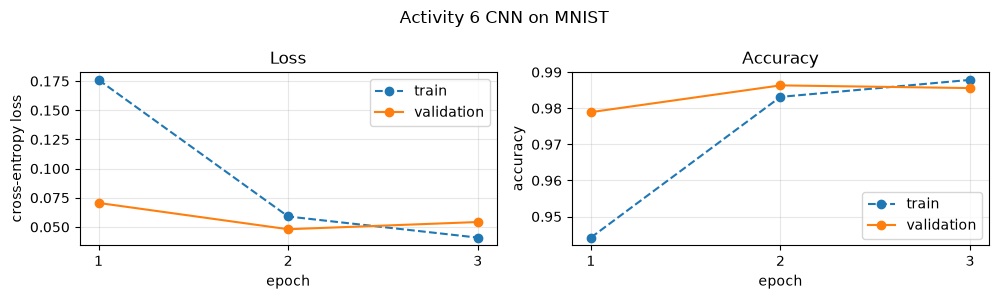

In [52]:
qd_model.load_state_dict(torch.load("model/best_QuickDrawCNN.pth"))
test_loss, test_acc = evaluate(qd_model, qd_test_loader)

lesson_acc = accuracy_score(true_labels.cpu(), pred_labels.cpu())
print(f"lesson CNN (softmax in forward, batch 10, 5 epochs): test accuracy {lesson_acc:.4f}")
print(f"Activity 6 CNN (logits, batch 32, 3 epochs)       : test accuracy {test_acc:.4f}")

ep_axis = range(1, len(qd_hist) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(ep_axis, [h[0] for h in qd_hist], "o--", label="train")
axes[0].plot(ep_axis, [h[2] for h in qd_hist], "o-", label="validation")
axes[0].set(xlabel="epoch", ylabel="cross-entropy loss", title="Loss")
axes[1].plot(ep_axis, [h[1] for h in qd_hist], "o--", label="train")
axes[1].plot(ep_axis, [h[3] for h in qd_hist], "o-", label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
for ax in axes:
    ax.set_xticks(list(ep_axis))
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Activity 6 CNN on MNIST")
plt.tight_layout()
plt.show()

**Interpretation.**

- **The architecture matches the diagram layer for layer.** The shape check reproduces every
  shape the diagram gives and fills in its `?` marks: 15×15 after MaxPool1 (because of
  `padding=1`), 7×7 after MaxPool2, 12,544 inputs to FCN1, and 10 outputs. The model has
  13,438,350 parameters, and 12,545,000 of them (93%) sit in FCN1, the dense layer right after
  the flatten. The convolutions do the feature extraction with under 3% of the weights.
- **It trains.** Validation accuracy reaches 98.63% at epoch 2. Restoring that best-validation
  checkpoint gives **98.78% test accuracy** on the 10,000 MNIST test images, against 97.88% for the
  lesson's CNN after 5 epochs.
- **Epoch 3 shows the first sign of overfitting.** Training loss keeps falling (0.059 → 0.041),
  but validation loss rises (0.048 → 0.054). That is why the checkpoint with the best validation
  accuracy is kept instead of the last one.
- **This is not a controlled comparison.** The two models differ in depth, width, batch size,
  epochs and the double-softmax issue, so the numbers show that the Activity 6 network works
  rather than which design choice caused the gain.